# Comparing dynamics

Local sweeps contain N² random-site attempts; cluster steps are whole Swendsen–Wang updates. These clocks are not equivalent computational costs.

Run cells in order. Install the package with the notebook extra first (see README).

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from ising import IsingModel, Simulator
from ising.experiments.trajectory import run

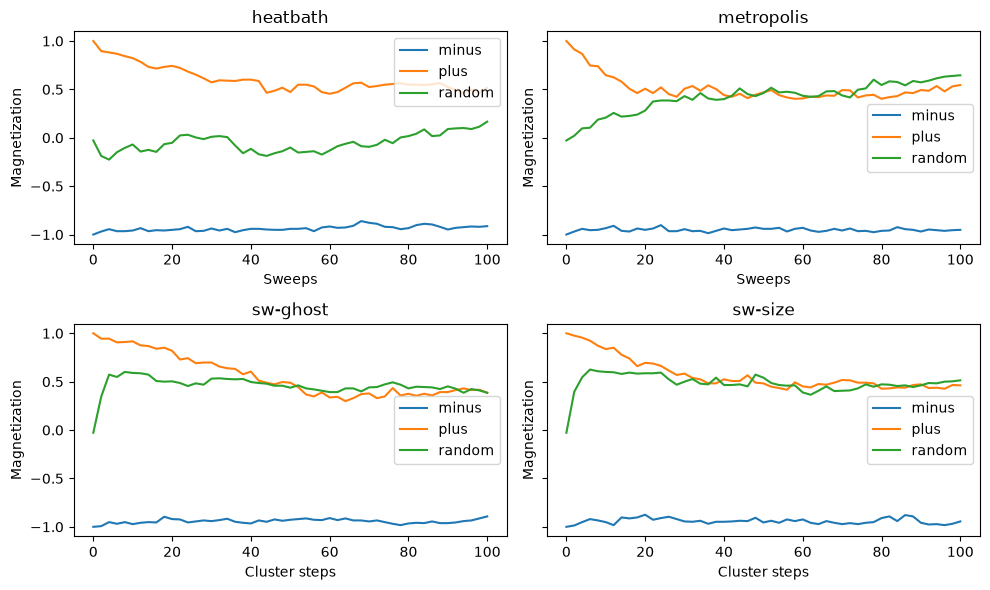

In [3]:
fig,axes=plt.subplots(2,2,figsize=(10,6),sharey=True)
for ax,k in zip(axes.flat,['heatbath','metropolis','sw-ghost','sw-size']):
    for init in ['minus','plus','random']:
        _,rows=run(IsingModel(24,.55,3.),100,init=init,dynamics=k,seed=42,record_every=2)
        ax.plot([r['sweep'] for r in rows],[r['magnetization'] for r in rows],label=init)
    ax.set(title=k,xlabel='Sweeps' if k in ['heatbath','metropolis'] else 'Cluster steps',ylabel='Magnetization'); ax.legend()
fig.tight_layout(); plt.show()